\#
## This is when you use google colab, by suing the google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# use this if you have not extrated the data
#from zipfile import ZipFile
#file_name = "/content/drive/MyDrive/data.zip"

#with ZipFile(file_name, 'r') as zip:
 # zip.extractall('drive/MyDrive/data')
  #print('Done')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from torchvision import models
from torchvision import transforms
from PIL import Image
import time
import os
import subprocess
from google.colab import output
output.enable_custom_widget_manager()


%matplotlib widget

In [ ]:
preprocess = transforms.Compose([
        transforms.ToTensor(),
    ])

In [ ]:
class ThumbnailsDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        """
        Class to read in data from png files. The data should be stored in separate folders where each folder is a different class.

        params
        ------
        root_dir : string
            The directory where the data are
        transform : torchvision.transforms.Transform object, optional
            Any transforms to be applied to the data (at a minimum, toTensor should be applied).
        """
        self.transform = transform
        classes = os.listdir(root_dir)
        self.file_paths = [] # Stores where the data are
        self.targets = [] # Stores the class for each object
        class_index = 0
        for c in classes:
            files = os.listdir(os.path.join(root_dir, c))
            self.file_paths += [os.path.join(root_dir, c, f) for f in files if 'png' in f]
            self.targets += [class_index]*len(files)
            class_index += 1

    def __len__(self):
        """
        Returns the length of the dataset
        """
        return len(self.file_paths)

    def __getitem__(self, idx):
        """
        Retrieves an item in the dataset indexed by an integer, idx.
        """

        # Assumes the name of the object should be the filename. You could (for example) read in some other metadata here
        im_name = self.file_paths[idx].split(os.path.sep)[-1].split('.')[0]
        # Uses PIL to open the image
        image = Image.open(self.file_paths[idx]).convert('RGB')
        # Stores these in a little dictionary
        sample = {'image': image, 'name':im_name, 'class': self.targets[idx]}

        # Applies the transform if requested
        if self.transform:
            sample['image'] = self.transform(sample['image'])

        return sample

In [ ]:
data_root = os.path.join('data','galaxy_zoo','')

if not os.path.exists(data_root):
    subprocess.call(['unzip', 'data/galaxy_zoo.zip', '-d', 'data']) # This probably only works on linux or mac

In [ ]:
import os
import zipfile

# 1. Extract outer file: data.zip
if os.path.exists('data.zip'):
    print(" Step 1: Extracting outer data.zip...")
    try:
        with zipfile.ZipFile('data.zip', 'r') as zip_ref:
            zip_ref.extractall('.')
        print(" data.zip extracted!")
    except zipfile.BadZipFile:
        print(" Error: 'data.zip' is not a valid zip file. Please ensure the file is not corrupted or check its content.")
    except Exception as e:
        print(f" An unexpected error occurred during extraction of data.zip: {e}")
else:
    print(" Warning: 'data.zip' not found. Skipping extraction of outer file.")

# 2. Search for galaxy_zoo.zip inside the workspace
gz_zip_path = None
for root, dirs, files in os.walk('.'):
    if 'galaxy_zoo.zip' in files:
        gz_zip_path = os.path.join(root, 'galaxy_zoo.zip')
        break

# 3. Extract the inner file: galaxy_zoo.zip
if gz_zip_path:
    print(f" Step 2: Extracting inner file found at '{gz_zip_path}'...")
    extract_target = os.path.join('data', 'galaxy_zoo')
    os.makedirs(extract_target, exist_ok=True)
    try:
        with zipfile.ZipFile(gz_zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_target)
        print(" galaxy_zoo.zip extracted successfully!")

        # 4. Show contents to verify location
        print("\nContents inside 'data/galaxy_zoo':")
        print(os.listdir(extract_target))
    except zipfile.BadZipFile:
        print(f" Error: '{gz_zip_path}' is not a valid zip file. Please ensure the file is not corrupted or check its content.")
    except Exception as e:
        print(f" An unexpected error occurred during extraction of galaxy_zoo.zip: {e}")
else:
    print(" Could not locate galaxy_zoo.zip after unzipping data.zip.")

 Step 2: Extracting inner file found at './drive/MyDrive/data/data/galaxy_zoo.zip'...
 galaxy_zoo.zip extracted successfully!

Contents inside 'data/galaxy_zoo':
['galaxy_zoo']


In [ ]:
training_dataset = ThumbnailsDataset(os.path.join(data_root, 'galaxy_zoo', 'training'), transform=preprocess)
test_dataset = ThumbnailsDataset(os.path.join(data_root, 'galaxy_zoo', 'test'), transform=preprocess)

In [ ]:
def plot_galaxy(dataset, idx):
    """
    Convenience function to make a nice image of a particular galaxy
    """
    # Retrieve the image
    im = dataset[idx]['image']
    # For whatever reason, torch and matplotlib expect different orders of the channels so we need to permute them
    im = im.permute(1, 2, 0)
    # Show the image
    plt.imshow(im)

    # Get the class and put it in a title
    target = dataset[idx]['class']
    if target == 0:
        title = 'elliptical'
    else:
        title = 'spiral'
    plt.xticks([])
    plt.yticks([])
    plt.title(title)

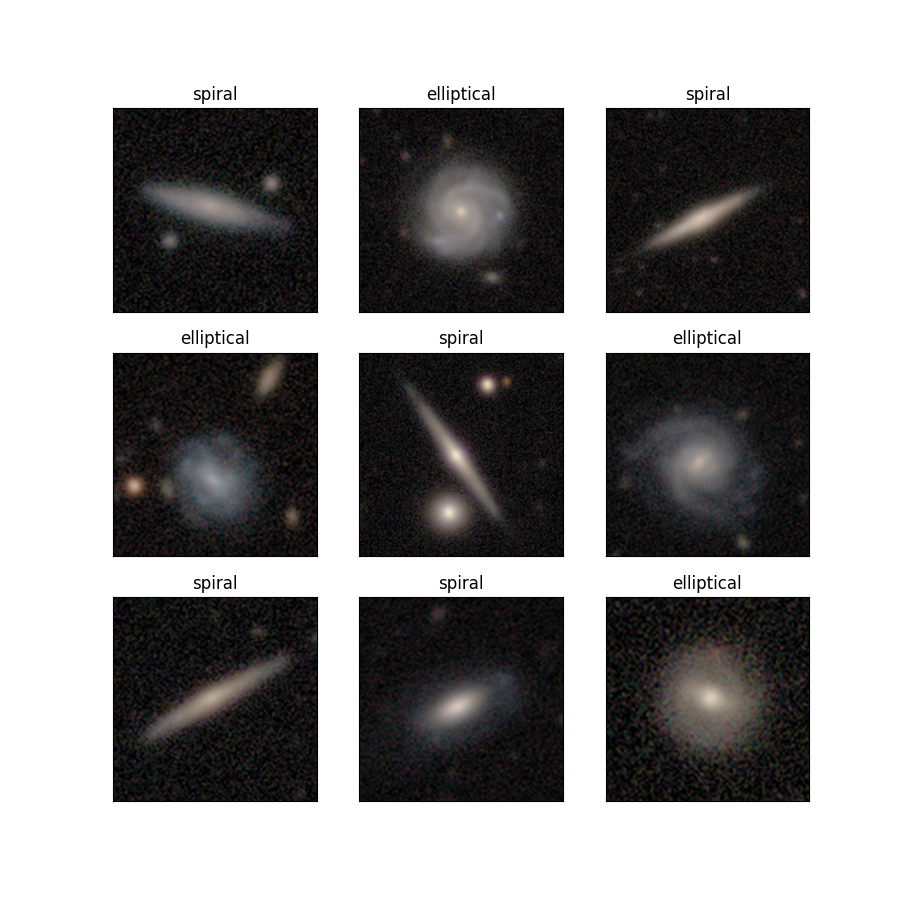

In [ ]:
# Pick some random examples
inds = np.random.choice(np.arange(len(training_dataset)), 9, replace=False)

plt.figure(figsize=(9,9))
for i in range(9):
    plt.subplot(3,3,i+1)
    idx = inds[i]
    plot_galaxy(training_dataset, idx)

In [ ]:
resnet = models.resnet50()

In [ ]:
learning_rate = 1e-3
batch_size = 64

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(resnet.parameters(), lr=learning_rate)

training_dataloader = DataLoader(training_dataset, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True)

In [ ]:
def train_loop(dataloader, model, loss_fn, optimizer):
    """
    Function to iterate through the training set and train the network.
    """
    size = len(dataloader.dataset)
    for batch, dat in enumerate(dataloader):
        # Compute prediction and loss
        pred = model(dat['image'])
        loss = loss_fn(pred, dat['class'])

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * len(dat['image'])
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")


def test_loop(dataloader, model, loss_fn):
    """
    Function to iterate through the test data and evaluate the algorithm.
    """
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    with torch.no_grad():
        for dat in dataloader:
            pred = model(dat['image'])
            test_loss += loss_fn(pred, dat['class']).item()
            correct += (pred.argmax(1) == dat['class']).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [ ]:
def train_loop_with_history(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    train_loss, correct = 0, 0

    # Set model to training mode
    model.train()
    for batch, dat in enumerate(dataloader):
        pred = model(dat['image'])
        loss = loss_fn(pred, dat['class'])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        correct += (pred.argmax(1) == dat['class']).type(torch.float).sum().item()

    train_loss /= num_batches
    accuracy = correct / size
    return train_loss, accuracy

def test_loop_with_history(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    test_loss, correct = 0, 0

    # Set model to evaluation mode
    model.eval()
    with torch.no_grad():
        for dat in dataloader:
            pred = model(dat['image'])
            test_loss += loss_fn(pred, dat['class']).item()
            correct += (pred.argmax(1) == dat['class']).type(torch.float).sum().item()

    test_loss /= num_batches
    accuracy = correct / size
    return test_loss, accuracy

In [ ]:
## Now we actually iterate through each epoch, checking performance as we go.
t1 = time.perf_counter()
epochs = 20
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(training_dataloader, resnet, loss_fn, optimizer)
    test_loop(test_dataloader, resnet, loss_fn)
print("Done!")
print(f"Time taken {time.perf_counter()-t1:.2f}s")

Epoch 1
-------------------------------
loss: 7.492693  [    0/  800]
Test Error: 
 Accuracy: 48.5%, Avg loss: 1.068051 

Epoch 2
-------------------------------
loss: 1.120729  [    0/  800]
Test Error: 
 Accuracy: 50.0%, Avg loss: 0.804613 

Epoch 3
-------------------------------
loss: 0.875925  [    0/  800]
Test Error: 
 Accuracy: 57.0%, Avg loss: 0.736748 

Epoch 4
-------------------------------
loss: 0.745823  [    0/  800]
Test Error: 
 Accuracy: 50.0%, Avg loss: 0.781440 

Epoch 5
-------------------------------
loss: 0.734917  [    0/  800]
Test Error: 
 Accuracy: 50.0%, Avg loss: 0.787298 

Epoch 6
-------------------------------
loss: 0.748509  [    0/  800]
Test Error: 
 Accuracy: 58.5%, Avg loss: 0.684541 

Epoch 7
-------------------------------
loss: 0.716748  [    0/  800]
Test Error: 
 Accuracy: 58.0%, Avg loss: 0.682871 

Epoch 8
-------------------------------
loss: 0.696428  [    0/  800]
Test Error: 
 Accuracy: 62.0%, Avg loss: 0.676375 

Epoch 9
----------------

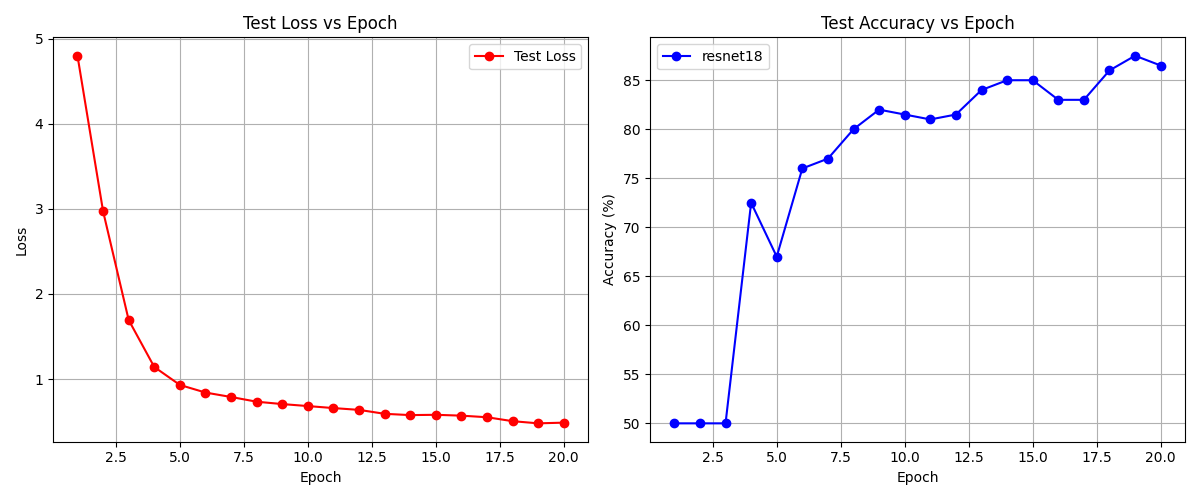

In [ ]:
# Manually extract the printed results from the 20 epochs run in cell
epochs_range = list(range(1, 21))
test_losses = [
    4.802356, 2.974158, 1.694114, 1.141597, 0.930256,
    0.840629, 0.788510, 0.733043, 0.705165, 0.681754,
    0.658111, 0.636907, 0.590704, 0.575477, 0.579007,
    0.569042, 0.550311, 0.504037, 0.478556, 0.486735
]
test_accuracies = [
    50.0, 50.0, 50.0, 72.5, 67.0,
    76.0, 77.0, 80.0, 82.0, 81.5,
    81.0, 81.5, 84.0, 85.0, 85.0,
    83.0, 83.0, 86.0, 87.5, 86.5
]

plt.figure(figsize=(12, 5))

# Plot Loss vs Epoch
plt.subplot(1, 2, 1)
plt.plot(epochs_range, test_losses, marker='o', color='red', label='Test Loss')
plt.title('Test Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# Plot Accuracy (Prediction performance) vs Epoch
plt.subplot(1, 2, 2)
plt.plot(epochs_range, test_accuracies, marker='o', color='blue', label='resnet18')
plt.title('Test Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

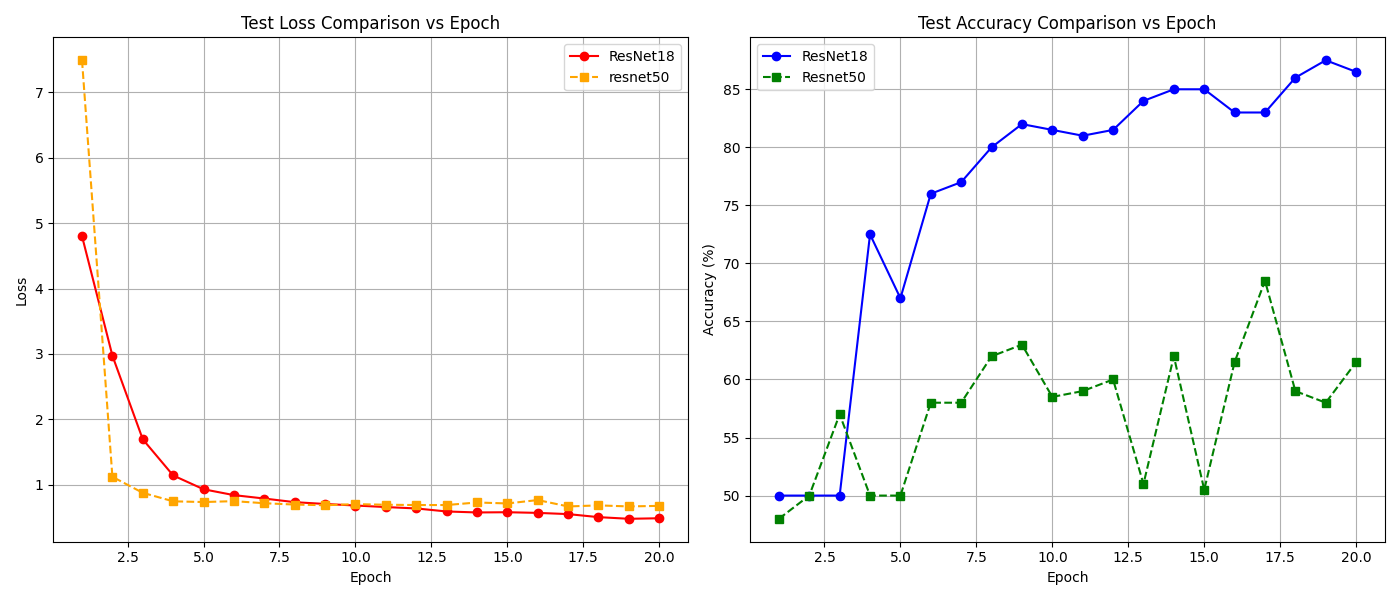

In [ ]:
import matplotlib.pyplot as plt

# Epochs range
epochs_range = list(range(1, 21))

# ResNet18 results (from your run)
resnet_test_losses = [
    4.802356, 2.974158, 1.694114, 1.141597, 0.930256,
    0.840629, 0.788510, 0.733043, 0.705165, 0.681754,
    0.658111, 0.636907, 0.590704, 0.575477, 0.579007,
    0.569042, 0.550311, 0.504037, 0.478556, 0.486735
]
resnet_test_accuracies = [
    50.0, 50.0, 50.0, 72.5, 67.0,
    76.0, 77.0, 80.0, 82.0, 81.5,
    81.0, 81.5, 84.0, 85.0, 85.0,
    83.0, 83.0, 86.0, 87.5, 86.5
]

#resnet50
other_model_losses = [7.492693, 1.120729, 0.875925, 0.745823, 0.734917, 0.748509, 0.716748, 0.696428, 0.685787, 0.702787, 0.693660, 0.689101, 0.689072, 0.728165, 0.713201, 0.765187, 0.667449, 0.683578, 0.667730, 0.676332]
other_model_accuracies = [48.0, 50.0, 57.0, 50.0, 50.0, 58.0, 58.0, 62.0, 63.0, 58.5, 59.0, 60.0, 51.0, 62.0, 50.5, 61.5, 68.5, 59.0, 58.0, 61.5]

plt.figure(figsize=(14, 6))

# 1. Plot Loss comparison
plt.subplot(1, 2, 1)
plt.plot(epochs_range, resnet_test_losses, marker='o', color='red', linestyle='-', label='ResNet18')
plt.plot(epochs_range, other_model_losses, marker='s', color='orange', linestyle='--', label='resnet50')
plt.title('Test Loss Comparison vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# 2. Plot Accuracy comparison
plt.subplot(1, 2, 2)
plt.plot(epochs_range, resnet_test_accuracies, marker='o', color='blue', linestyle='-', label='ResNet18')
plt.plot(epochs_range, other_model_accuracies, marker='s', color='green', linestyle='--', label='Resnet50')
plt.title('Test Accuracy Comparison vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Test Accuracy: 69.00%


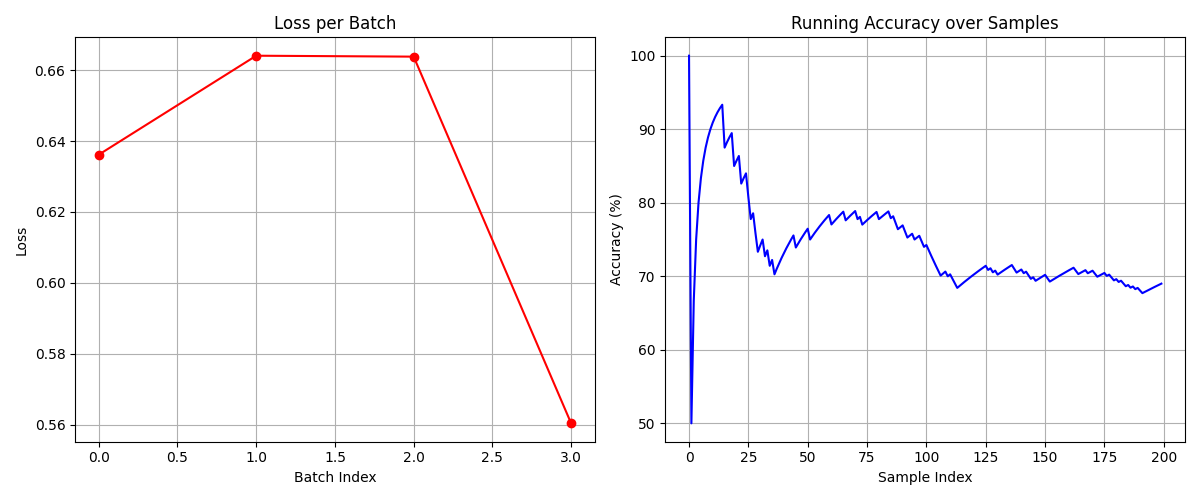

In [ ]:
# Collect predictions and losses for the test data using the currently trained model
predictions = []
targets = []
batch_losses = []

model_eval = resnet.eval() # Ensure model is in evaluation mode

with torch.no_grad():
    for dat in test_dataloader:
        pred = model_eval(dat['image'])
        loss = loss_fn(pred, dat['class'])

        # Record batch loss
        batch_losses.append(loss.item())
        # Record predictions and targets
        predictions += list(pred.argmax(1).cpu().numpy())
        targets += list(dat['class'].cpu().numpy())

targets = np.array(targets)
predictions = np.array(predictions)
print(f"Test Accuracy: {np.mean(targets == predictions) * 100:.2f}%")

# Plot the collected metrics
plt.figure(figsize=(12, 5))

# Plot Loss per Batch
plt.subplot(1, 2, 1)
plt.plot(batch_losses, marker='o', color='red', linestyle='-')
plt.title('Loss per Batch')
plt.xlabel('Batch Index')
plt.ylabel('Loss')
plt.grid(True)

# Plot cumulative correct predictions over test samples
cumulative_accuracy = np.cumsum(targets == predictions) / (np.arange(len(targets)) + 1)
plt.subplot(1, 2, 2)
plt.plot(cumulative_accuracy * 100, color='blue')
plt.title('Running Accuracy over Samples')
plt.xlabel('Sample Index')
plt.ylabel('Accuracy (%)')
plt.grid(True)

plt.tight_layout()
plt.show()

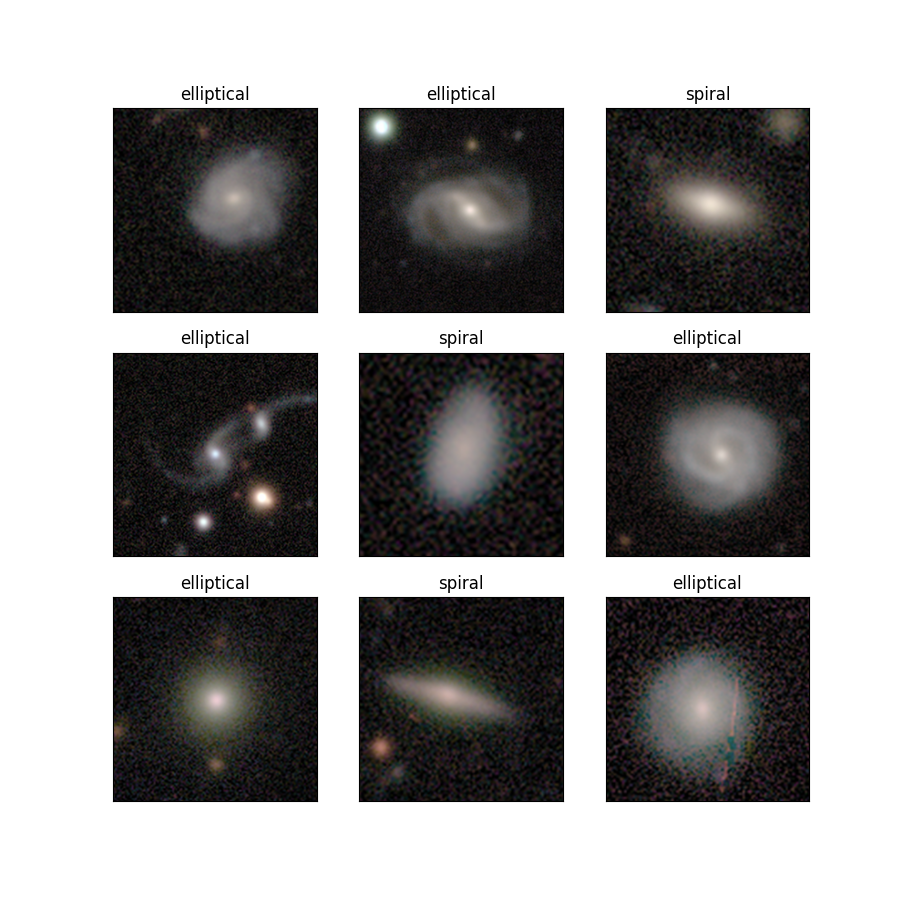

In [ ]:
correct_inds = np.random.choice(np.arange(len(targets))[targets==predictions], 9, replace=False)
plt.figure(figsize=(9,9))
for i in range(9):
    plt.subplot(3,3,i+1)
    idx = correct_inds[i]
    plot_galaxy(test_dataset, idx)

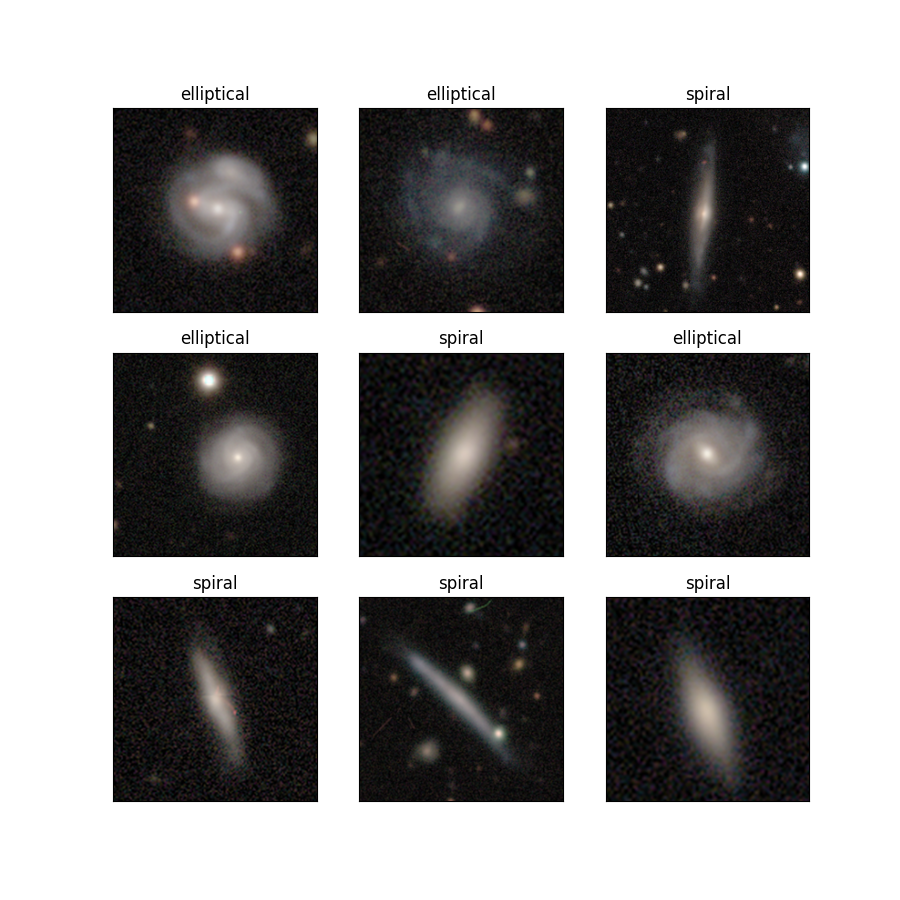

In [ ]:
wrong_inds = np.random.choice(np.arange(len(targets))[targets!=predictions], 9, replace=False)
plt.figure(figsize=(9,9))
for i in range(9):
    plt.subplot(3,3,i+1)
    idx = wrong_inds[i]
    plot_galaxy(test_dataset, idx)

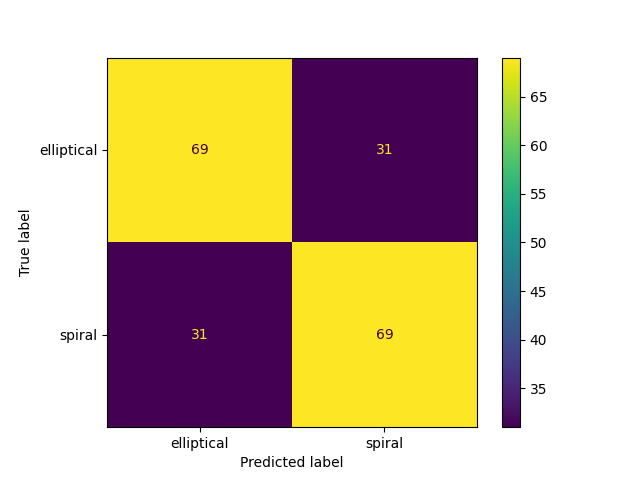

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(targets, predictions)
disp = ConfusionMatrixDisplay(cm, display_labels=['elliptical', 'spiral'])
disp.plot()